In [17]:
from pathlib import Path
import json
import platform

import numpy as np
import pandas as pd
import scipy
from scipy import sparse
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

In [19]:
# Set a specific path to reuse a particular Week 3 run.
run_dir = None
root = Path("cleaned_data")

required_files = ["X_train.npz", "X_test.npz", 
                  "y_train.csv", "y_test.csv",
                  "train_cleaned.csv", "test_cleaned.csv", 
                  "encoded_features.csv", "run_summary.json"]

# If no path is given, choose the most recent complete timestamped export.
if run_dir is None:
    complete_runs = []
    for folder in sorted(root.glob("run_*")):
        if all((folder / name).is_file() for name in required_files):
            complete_runs.append(folder)
    if not complete_runs:
        raise FileNotFoundError("No complete Week 3 export found. Run the Week 3 export cells "
                                "first, or set run_dir to your actual output folder.")
    run_dir = complete_runs[-1]

run_dir = Path(run_dir).resolve()
for name in required_files:
    if not (run_dir / name).is_file():
        raise FileNotFoundError(run_dir / name)

output_dir = run_dir / "week4_baseline"
print("Week 3 input folder:", run_dir)
print("Week 4 output folder:", output_dir)

Week 3 input folder: /Users/jingying/Documents/IDX Exchange/py/cleaned_data/run_20261014_180636_999980
Week 4 output folder: /Users/jingying/Documents/IDX Exchange/py/cleaned_data/run_20261014_180636_999980/week4_baseline


In [21]:
# Load the processed matrices without changing their column or row order.
X_train = sparse.load_npz(run_dir / "X_train.npz").tocsr()
X_test = sparse.load_npz(run_dir / "X_test.npz").tocsr()

# Each target file contains row_id and ClosePrice, in matrix row order.
train_labels = pd.read_csv(run_dir / "y_train.csv")
test_labels = pd.read_csv(run_dir / "y_test.csv")
y_train = train_labels["ClosePrice"].to_numpy(dtype=float)
y_test = test_labels["ClosePrice"].to_numpy(dtype=float)

feature_names = pd.read_csv(run_dir / "encoded_features.csv")["feature"].tolist()
summary = json.loads((run_dir / "run_summary.json").read_text())

# Read only metadata needed for the split and alignment checks.
metadata_cols = ["row_id", "CloseDate", "ClosePrice"]
train_info = pd.read_csv(run_dir / "train_cleaned.csv", usecols=metadata_cols, parse_dates=["CloseDate"])
test_info = pd.read_csv(run_dir / "test_cleaned.csv", usecols=metadata_cols, parse_dates=["CloseDate"])

print("Training matrix:", X_train.shape)
print("\nTest matrix:", X_test.shape)
print("\nSelected training window:", summary["best_X"], "months")
print("\nTraining period:", summary["train_start"], "through", summary["train_end"])
print("\nReserved test month:", summary["test_month"])
print("\nWindow-selection metric:", summary["selection_metric"])
print("\nNumeric inputs:", summary["numeric_inputs"])
print("\nCategorical inputs:", summary["categorical_inputs"])
print("\nAll model inputs:", summary["feature_cols"])

Training matrix: (264531, 497)

Test matrix: (12458, 497)

Selected training window: 24 months

Training period: 2024-04 through 2026-03

Reserved test month: 2026-04

Window-selection metric: Mean monthly validation MdAPE on all quality-cleaned validation records

Numeric inputs: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'PropertyAge', 'BedBathRatio', 'MonthSin', 'MonthCos', 'TimeIndex']

Categorical inputs: ['PostalCode', 'City', 'CountyOrParish', 'SubdivisionName', 'HighSchoolDistrict', 'GeoCluster']

All model inputs: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'PropertyAge', 'BedBathRatio', 'MonthSin', 'MonthCos', 'TimeIndex', 'PostalCode', 'City', 'CountyOrParish', 'SubdivisionName', 'HighSchoolDistrict', 'GeoCluster', 'HistoricPPSF', 'LivingArea_missing', 'BedroomsTotal_missing', 'BathroomsTotalInteger_missing', 'LotSizeSquareFeet_miss

In [23]:
# Confirm that every row has a label and both matrices use the same features.
assert X_train.shape[0] == len(y_train) == summary["train_rows"]
assert X_test.shape[0] == len(y_test) == summary["test_rows"]
assert X_train.shape[1] == X_test.shape[1] == len(feature_names)
assert X_train.shape[1] > 0 and len(y_train) >= 2 and len(y_test) >= 2

# Verify row order against the readable exports; do not sort labels separately.
assert np.array_equal(train_labels["row_id"], train_info["row_id"])
assert np.array_equal(test_labels["row_id"], test_info["row_id"])
assert np.allclose(y_train, train_info["ClosePrice"])
assert np.allclose(y_test, test_info["ClosePrice"])
assert train_labels["row_id"].is_unique and test_labels["row_id"].is_unique
assert set(train_labels["row_id"]).isdisjoint(test_labels["row_id"])

# Confirm that targets and processed inputs are valid numbers.
assert np.isfinite(X_train.data).all() and np.isfinite(X_test.data).all()
assert np.isfinite(y_train).all() and np.isfinite(y_test).all()
assert (y_train > 0).all() and (y_test > 0).all()

test_month = pd.Period(summary["test_month"], freq="M")
train_months = train_info["CloseDate"].dt.to_period("M")
test_months = test_info["CloseDate"].dt.to_period("M")
assert train_months.between(test_month - summary["best_X"], test_month - 1).all()
assert test_months.eq(test_month).all()
assert train_info["CloseDate"].max() < test_info["CloseDate"].min()

# Audit the raw input list saved by Week 3, not the encoded column names.
excluded_inputs = {
    "ClosePrice", "ListPrice", "OriginalListPrice", "DaysOnMarket",
    "CloseDate", "PurchaseContractDate", "ListingContractDate",
    "ListingKey", "UnparsedAddress", "row_id", "source_file", "source_row"
}
assert excluded_inputs.isdisjoint(summary["feature_cols"])
print("Alignment, numerical, and chronological checks passed.")

Alignment, numerical, and chronological checks passed.


In [25]:
# Create an ordinary, unpenalized Linear Regression with an intercept.
baseline_model = LinearRegression()

# Learn coefficients from the processed training data only.
baseline_model.fit(X_train, y_train)

print("Linear Regression training completed.")
print("Number of processed input features:", baseline_model.n_features_in_)

Linear Regression training completed.
Number of processed input features: 497


In [27]:
# Predict the reserved test month once and reuse these predictions below.
y_pred = baseline_model.predict(X_test)

# Check that all predictions are finite numbers (no NaN or infinity).
assert np.isfinite(y_pred).all(), "Predictions contain NaN or infinite values."

# Keep raw predictions, including negative values, for honest evaluation.
predictions = pd.DataFrame({
    "row_id": test_labels["row_id"].to_numpy(),
    "CloseDate": test_info["CloseDate"].to_numpy(),
    "ActualClosePrice": y_test,
    "PredictedClosePrice": y_pred
})
predictions["Residual"] = y_test - y_pred
predictions["AbsoluteError"] = np.abs(y_test - y_pred)
predictions["APE_pct"] = 100 * predictions["AbsoluteError"] / y_test

display(predictions.head().round(2))
print("Negative test predictions:", int((y_pred < 0).sum()))

,row_id,CloseDate,ActualClosePrice,PredictedClosePrice,Residual,AbsoluteError,APE_pct
0,591446,2026-04-24,1750000.0,1913913.96,-163913.96,163913.96,9.37
1,591448,2026-04-30,600000.0,921701.36,-321701.36,321701.36,53.62
2,591450,2026-04-27,3625000.0,3325611.27,299388.73,299388.73,8.26
3,591451,2026-04-30,1450000.0,1376406.92,73593.08,73593.08,5.08
4,591452,2026-04-30,1500000.0,1631952.55,-131952.55,131952.55,8.80


Negative test predictions: 50


In [29]:
# Reuse Week 3 thresholds. Never calculate new percentiles from the test set.
low, high = summary["price_bounds"]
in_range = (y_test >= low) & (y_test <= high)
assert int(in_range.sum()) == summary["test_avm_range_rows"]

scope_counts = pd.DataFrame({
    "scope": ["full_test_month", "within_training_price_bounds"],
    "rows": [len(y_test), int(in_range.sum())]
})
scope_counts["coverage_pct"] = 100 * scope_counts["rows"] / len(y_test)
print(f"Frozen training price bounds: ${low:,.2f} to ${high:,.2f}")
print("Test records outside these bounds:", int((~in_range).sum()))
display(scope_counts.round(2))

Frozen training price bounds: $190,000.00 to $8,476,225.00
Test records outside these bounds: 137


,scope,rows,coverage_pct
0,full_test_month,12458,100.0
1,within_training_price_bounds,12321,98.9


In [31]:
# Calculate the same metrics for each clearly labeled evaluation population.
result_rows = []
scopes = {
    "full_test_month": np.ones(len(y_test), dtype=bool),
    "within_training_price_bounds": in_range
}

for scope, rows in scopes.items():
    actual = y_test[rows]
    predicted = y_pred[rows]
    r2 = np.nan
    mae = np.nan
    mape = np.nan
    mdape = np.nan

    if len(actual) > 0:
        percentage_error = 100 * np.abs(actual - predicted) / actual
        mae = mean_absolute_error(actual, predicted)
        mape = percentage_error.mean()
        mdape = np.median(percentage_error)
    if len(actual) >= 2 and np.unique(actual).size > 1:
        r2 = r2_score(actual, predicted)

    result_rows.append({
        "model": "LinearRegression",
        "scope": scope,
        "test_month": str(test_month),
        "training_window_months": summary["best_X"],
        "train_rows": len(y_train),
        "test_rows": len(actual),
        "encoded_features": X_train.shape[1],
        "R2": r2,
        "MAE_dollars": mae,
        "MAPE_pct": mape,
        "MdAPE_pct": mdape,
        "negative_predictions": int((predicted < 0).sum())
    })

baseline_results = pd.DataFrame(result_rows)
display(baseline_results.round(4))

,model,scope,test_month,training_window_months,train_rows,test_rows,encoded_features,R2,MAE_dollars,MAPE_pct,MdAPE_pct,negative_predictions
0,LinearRegression,full_test_month,2026-04,24,264531,12458,497,0.0091,490192.7551,25.0358,17.5422,50
1,LinearRegression,within_training_price_bounds,2026-04,24,264531,12321,497,0.8034,260169.4344,24.2702,17.3720,33


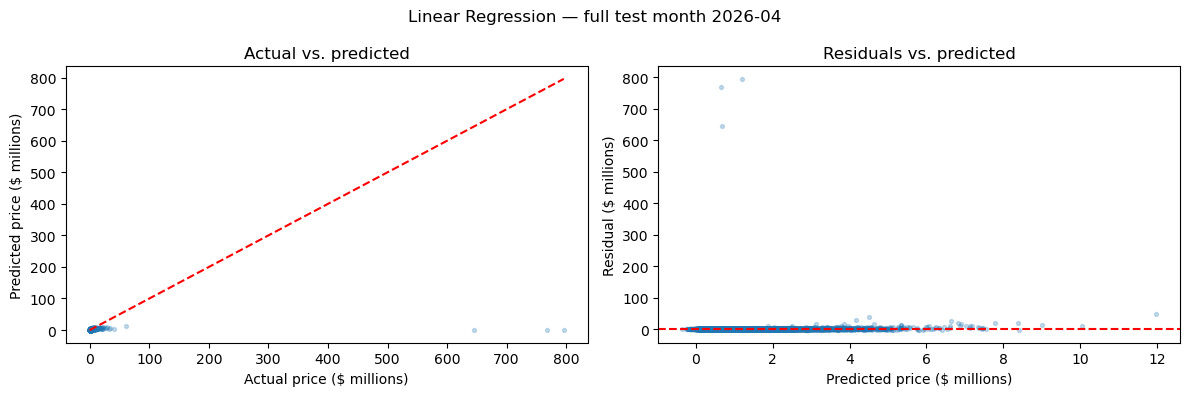

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Show dollar amounts in millions to keep axis labels readable.
axes[0].scatter(y_test / 1e6, y_pred / 1e6, s=8, alpha=0.25)
plot_min = min(y_test.min(), y_pred.min()) / 1e6
plot_max = max(y_test.max(), y_pred.max()) / 1e6
axes[0].plot([plot_min, plot_max], [plot_min, plot_max], "r--")
axes[0].set(xlabel="Actual price ($ millions)",
            ylabel="Predicted price ($ millions)", title="Actual vs. predicted")

axes[1].scatter(y_pred / 1e6, (y_test - y_pred) / 1e6, s=8, alpha=0.25)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted price ($ millions)",
            ylabel="Residual ($ millions)", title="Residuals vs. predicted")
fig.suptitle(f"Linear Regression — full test month {test_month}")
fig.tight_layout()
plt.show()

In [35]:
training_median = np.median(y_train)
band_rows = []

for band, rows in {
    "At or below training median": y_test <= training_median,
    "Above training median": y_test > training_median
}.items():
    errors = predictions.loc[rows]
    band_rows.append({
        "price_band": band,
        "test_rows": len(errors),
        "MAE_dollars": errors["AbsoluteError"].mean(),
        "MAPE_pct": errors["APE_pct"].mean(),
        "MdAPE_pct": errors["APE_pct"].median()
    })

price_band_results = pd.DataFrame(band_rows)
print(f"Training median price used for the bands: ${training_median:,.2f}")
display(price_band_results.round(2))

Training median price used for the bands: $899,000.00


,price_band,test_rows,MAE_dollars,MAPE_pct,MdAPE_pct
0,At or below training median,6058,171464.85,31.62,23.09
1,Above training median,6400,791888.64,18.80,14.07


In [37]:
output_dir.mkdir(parents=True, exist_ok=True)

# Keep full precision in saved results; round only the displayed tables.
baseline_results.to_csv(output_dir / "baseline_results.csv", index=False)
predictions.to_csv(output_dir / "baseline_test_predictions.csv", index=False)
price_band_results.to_csv(output_dir / "baseline_price_band_results.csv", index=False)
scope_counts.to_csv(output_dir / "test_scope_counts.csv", index=False)
fig.savefig(output_dir / "baseline_diagnostics.png", dpi=150, bbox_inches="tight")

# Store the model and its input contract together.
joblib.dump({
    "model": baseline_model,
    "encoded_feature_names": feature_names,
    "week3_run_dir": str(run_dir),
    "test_month": str(test_month),
    "training_window_months": summary["best_X"],
    "price_bounds": [low, high],
    "input_type": "Week 3 processed matrix in encoded_feature_names order"
}, output_dir / "linear_regression_baseline.joblib")

versions = {
    "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__
}
(output_dir / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in versions.items()) + "\n"
)
run_details = {
    "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "python_version": platform.python_version(),
    "versions": versions,
    "week3_run_dir": str(run_dir),
    "week3_summary": summary,
    "model_parameters": baseline_model.get_params(),
    "target": "ClosePrice in original dollars",
    "prediction_clipping": "None",
    "price_band_threshold": float(training_median)
}
(output_dir / "baseline_run_details.json").write_text(
    json.dumps(run_details, indent=2), encoding="utf-8"
)
print("Baseline files saved to:", output_dir)

Baseline files saved to: /Users/jingying/Documents/IDX Exchange/py/cleaned_data/run_20261014_180636_999980/week4_baseline


In [39]:
# Generate a concise English report from the actual run results.
report_lines = [
    "# Week 4 — Linear Regression Baseline", "",
    f"Week 3 source folder: {run_dir.name}",
    f"Training period: {summary['train_start']} through {summary['train_end']}.",
    f"Selected training window: {summary['best_X']} months.",
    f"Test month: {test_month}.",
    f"Retained training observations: {len(y_train):,}.",
    f"Processed input columns: {X_train.shape[1]:,}.",
    "Target: ClosePrice in dollars; predictions are not clipped.",
    f"Frozen training price bounds: ${low:,.2f} to ${high:,.2f}.", ""
]

for _, result in baseline_results.iterrows():
    report_lines.extend([
        f"## {result['scope']}",
        f"Test observations: {int(result['test_rows']):,}.",
        f"R^2: {result['R2']:.4f}.",
        f"MAE: ${result['MAE_dollars']:,.2f}.",
        f"MAPE: {result['MAPE_pct']:.2f}%.",
        f"MdAPE: {result['MdAPE_pct']:.2f}%.",
        f"Negative predictions: {int(result['negative_predictions'])}.", ""
    ])

report_text = "\n".join(report_lines) + "\n"
(output_dir / "baseline_report.md").write_text(report_text, encoding="utf-8")
print(report_text)

# Week 4 — Linear Regression Baseline

Week 3 source folder: run_20261014_180636_999980
Training period: 2024-04 through 2026-03.
Selected training window: 24 months.
Test month: 2026-04.
Retained training observations: 264,531.
Processed input columns: 497.
Target: ClosePrice in dollars; predictions are not clipped.
Frozen training price bounds: $190,000.00 to $8,476,225.00.

## full_test_month
Test observations: 12,458.
R^2: 0.0091.
MAE: $490,192.76.
MAPE: 25.04%.
MdAPE: 17.54%.
Negative predictions: 50.

## within_training_price_bounds
Test observations: 12,321.
R^2: 0.8034.
MAE: $260,169.43.
MAPE: 24.27%.
MdAPE: 17.37%.
Negative predictions: 33.


